In [ ]:
pip install ugot

In [30]:
from ugot import ugot
got = ugot.UGOT()
got.initialize('192.168.88.1')
print("Hello World")
got.play_audio_tts("Hello World!", 0, False)

192.168.88.1:50051
Hello World


In [31]:
# OpenCV related import
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image,display, clear_output
import os

In [32]:
# import YOLO
import ultralytics
from ultralytics import YOLO
import cv2
from IPython.display import Image, display

ultralytics.checks()
model = YOLO("yolo26n.pt")
print("Model is ready.")

Ultralytics 8.4.128 🚀 Python-3.14.6 torch-2.13.0 CPU (Apple M5 Pro)
Setup complete ✅ (18 CPUs, 64.0 GB RAM, 256.9/926.3 GB disk)
Model is ready.


In [ ]:
Laser1 = got.read_distance_data(21)
Laser2 = got.read_distance_data(51)

print("The value for IR1 is:",Laser1)
print("The value for IR2 is:",Laser2)

# Level 4 Term2

## Session 1

In [ ]:
my_friend1=["apple",1000,"Mars",True,["red","yellow"]]
my_friend2=("apple",1000,"Mars",True,["red","yellow"])
print(my_friend1)
print(my_friend2)
print(type(my_friend1))
print(type(my_friend2))
print(my_friend2[4][0])
print(my_friend1[:])
print(my_friend1[1:3])
print(my_friend2[::2])
print(my_friend2[::-1])

In [ ]:
my_friend3 = {
    "Name":"Jack",
    "Age":1000,
    "Birth place":"Sun",
    "Fruit":["apple","banana","orange"],
    "Color":"blue",
}
print(my_friend3)
print(my_friend3["Color"])
print(my_friend3.keys())
print(my_friend3.values())
print(my_friend3.items())
my_friend3["Name"]="Tom"
print(my_friend3)

1. OpenCV

In [ ]:
pip install opencv-python

In [ ]:
pip install matplotlib

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image,display

2. display image and inspect its data

In [ ]:
Image("eagle.jpg")

In [ ]:
eagle=cv2.imread("eagle.jpg")
print("Loaded:",eagle is not None)
if eagle is not None:
    print("Shape(H,W,C):",eagle.shape)
    print("dtype:",eagle.dtype)
    print("Top-left pixel(B,G,R):",eagle[0,0])

## Session 2

1. Array

In [ ]:
arrays1 = [1,2,3,4,5,6]
print(arrays1)
print(type(arrays1))

In [ ]:
arrays1 = [1,2,3,4,5,6] # arrays demands the same data type itmes
list1 = [1,"apple",True,["red","blue"]]
print(type(arrays1))
print(type(list1))

2. Arrays in Numpy

In [ ]:
import numpy as np
# 1D array
array1d = np.array([1,2,3,4,5,6])
print(f"1D Arrays:{array1d}")
print(f"Shape:{array1d.shape}")
print(type(array1d))

In [ ]:
# 2D array
array2d = np.array([[1,2,3],
                    [4,5,6]])
print(f"2D Arrays:\n{array2d}")
print(f"Shape:{array2d.shape}")
print(type(array2d))

In [ ]:
# 3D array
array3d=np.array([[[255,0,0],[0,255,0],[0,0,255]],
                  [[0,0,255],[0,255,0],[255,0,0]]])
print(f"3D Arrays:\n{array3d}")
print(f"Shape:{array3d.shape}")
print(type(array3d))

In [ ]:
Image("Array.png")

3. UGOT image display

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Step 1: turn on the camera
got.open_camera()
print("The camera is on.")

# Step 2: get the raw data
picture = got.read_camera_data()
print(f"The raw data:{picture}")
print(f"Data type:{type(picture)}")

# Step 3: unpack the raw data, bytes to 1D array
picture  = np.frombuffer(picture,np.uint8)
print(f"The data:{picture}")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 4: 1D array to 3D array
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
print(f"The data:{picture}")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 5: pack the 3D array for Jupyter
ok,picture_jpg = cv2.imencode(".jpg",picture)
print(f"The data:{picture}")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 6: show the image on the screen
display(Image(picture_jpg.tobytes()))

## Session 3

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
picture = got.read_camera_data()
picture  = np.frombuffer(picture,np.uint8)
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
ok,picture_jpg = cv2.imencode(".jpg",picture)
display(Image(picture_jpg.tobytes()))

In [ ]:
Image("Robot camera to image-2.png")

1. change photos to video

In [ ]:
import numpy as np
import cv2
from IPython.display import clear_output,display, Image

got.open_camera()
print("The camera is on.")

for i in range(100):
    picture = got.read_camera_data()

    if picture is None:
        continue

    picture  = np.frombuffer(picture,np.uint8)
    picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
    ok,picture_jpg = cv2.imencode(".jpg",picture)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

In [ ]:
Laser1 = got.read_distance_data(21)
Laser2 = got.read_distance_data(51)
print(Laser1)
print(Laser2)

## Session 4

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
picture = got.read_camera_data()
picture  = np.frombuffer(picture,np.uint8)
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
ok,picture_jpg = cv2.imencode(".jpg",picture)
display(Image(picture_jpg.tobytes()))

1. Motion detection robot

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")

while True:
    Laser1 = got.read_distance_data(21)
    picture = got.read_camera_data()

    if Laser1>50:
        got.show_light_rgb_effect(0,255,0,3)
        time.sleep(0.1)
    
    else:
        if picture is None:
            print("No data founded")
            continue
        
        picture  = np.frombuffer(picture,np.uint8)
        picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
        ok,picture_jpg = cv2.imencode(".jpg",picture)
        display(Image(picture_jpg.tobytes()))
        got.show_light_rgb_effect(255,0,0,3)
        time.sleep(2)
        got.turn_off_lights()
        got.play_audio_tts("Gotcha, ha ha ha", 0, False)
        break


2. Spin robot patrol

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")

while True:
    Laser1 = got.read_distance_data(21)
    picture = got.read_camera_data()

    if Laser1>50:
        got.mecanum_turn_speed(2,20)
        got.show_light_rgb_effect(0,255,0,3)
        time.sleep(0.1)
    
    else:
        if picture is None:
            print("No data founded")
            continue
        
        got.mecanum_stop()
        picture  = np.frombuffer(picture,np.uint8)
        picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
        ok,picture_jpg = cv2.imencode(".jpg",picture)
        display(Image(picture_jpg.tobytes()))
        got.show_light_rgb_effect(255,0,0,3)
        time.sleep(2)
        got.turn_off_lights()
        got.play_audio_tts("Gotcha, ha ha ha", 0, False)
        break

3.Sweeper robot patrol

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

# Step1: create the photo taking function
def take_photo():
    picture = got.read_camera_data()
    if picture is None:
        print("No data founded")
        return
    
    got.mecanum_stop()
    picture  = np.frombuffer(picture,np.uint8)
    picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
    ok,picture_jpg = cv2.imencode(".jpg",picture)
    display(Image(picture_jpg.tobytes()))
    got.show_light_rgb_effect(255,0,0,3)
    time.sleep(2)
    got.turn_off_lights()
    got.play_audio_tts("Gotcha, ha ha ha", 0, False)

# step2: start sweeping
got.open_camera()
print("The camera is on.")

while True:
    # sweep from left to right
    for i in range(16): 
        Laser1 = got.read_distance_data(21)

        if Laser1>50:
            got.mecanum_turn_speed(2,20)
            got.show_light_rgb_effect(0,255,0,3)
            time.sleep(0.5)
        else:
            got.mecanum_stop()
            take_photo()
            break
    if Laser1<50:
        break
    # sweep from right to left
    for i in range(16): 
        Laser1 = got.read_distance_data(21)

        if Laser1>50:
            got.mecanum_turn_speed(3,20)
            got.show_light_rgb_effect(0,255,0,3)
            time.sleep(0.5)
        else:
            got.mecanum_stop()
            take_photo()
            break
    if Laser1<50:
        break

got.mecanum_stop()
print("Mission completed.")

## Session 5

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
picture = got.read_camera_data()
picture  = np.frombuffer(picture,np.uint8)
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
ok,picture_jpg = cv2.imencode(".jpg",picture)
display(Image(picture_jpg.tobytes()))

1. BGR to HSV

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

ok,picture_hsv = cv2.imencode(".jpg",picture_hsv)
display(Image(picture_hsv.tobytes()))

2. Red color detection

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Open the camera and get data
got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

#Decode the picture
picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the red color
lower_red = np.array([20,80,80])
upper_red = np.array([180,255,255])

# create a mask-red only pixel
mask = cv2.inRange(picture_hsv,lower_red,upper_red)

# Show the black-white image
ok,mask = cv2.imencode(".jpg",mask)
display(Image(mask.tobytes()))

In [ ]:
Image("Color wheel.png")

In [ ]:
Image("BGR2HSV.png")

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Open the camera and get data
got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

#Decode the picture
picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the red color
lower_yellow = np.array([20,0,0])
upper_yellow = np.array([35,255,255])

# create a mask-red only pixel
mask = cv2.inRange(picture_hsv,lower_yellow,upper_yellow)

# Show the black-white image
ok,mask = cv2.imencode(".jpg",mask)
display(Image(mask.tobytes()))

## Session 6

1. Yellow only detection

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Open the camera and get data
got.open_camera()
picture_raw = got.read_camera_data()
if picture_raw is None:
    raise Exception("No camera data found.")

#Decode the picture
picture_1D  = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the yellow color
lower_yellow = np.array([25,160,160])
upper_yellow = np.array([60,225,225])

# create a mask-yellow only pixel
mask = cv2.inRange(picture_hsv,lower_yellow,upper_yellow)

# Show the black-white image
ok,mask = cv2.imencode(".jpg",mask)
display(Image(mask.tobytes()))

2. Yellow only image show

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Open the camera and get data
got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

#Decode the picture
picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the yellow color
lower_yellow = np.array([25,150,150])
upper_yellow = np.array([60,225,225])

# create a mask-yellow only pixel
mask = cv2.inRange(picture_hsv,lower_yellow,upper_yellow)

# Show the yellow image
yellow_only = cv2.bitwise_and(picture_bgr,picture_bgr,mask=mask)

# Show the yellow only image
ok,yellow_only = cv2.imencode(".jpg",yellow_only)
display(Image(yellow_only.tobytes()))

In [ ]:
Image("Yellow only.png")

3. Bounding box

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Open the camera and get data
got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

#Decode the picture
picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the yellow color
lower_yellow = np.array([20,100,100])
upper_yellow = np.array([60,225,255])

# create a mask-yellow only pixel
mask = cv2.inRange(picture_hsv,lower_yellow,upper_yellow)

# Find contours(outlines of the white area in the mask)
contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

#Loop through contours and draw bounding boxes
for contour in contours:
    area = cv2.contourArea(contour)
    if area>500:
        x,y,w,h=cv2.boundingRect(contour)
        cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),2)

# Show the yellow only image with bounding box
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

## Session 7

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

1. UGOT camera color picker

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# get the picture size
height = picture_hsv.shape[0]
width =picture_hsv.shape[1]

#find the center point
center_x = width // 2
center_y = height // 2

# read the HSV values, show it with the command: image[y,x] (row first, then column)
h = picture_hsv[center_y,center_x,0]  # H=hue(color)
s = picture_hsv[center_y,center_x,1]  # S=saturation(how vivid)
v = picture_hsv[center_y,center_x,2]  # V=value(brightness)

print(f"H = {h}")
print(f"S = {s}")
print(f"V = {v}")

# draw a small circle at the center of the camera
cv2.circle(picture_bgr,(center_x,center_y),10,(0,255,0),2)

# show the image with the circle
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

2. bounding box with video

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
if picture_raw is None:
    raise Exception("No raw.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("No bgr.")

# handle is for live updates in Jupyter
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(picture_jpg.tobytes()),display_id= True)

# Detect the color
lower_color = np.array([80,200,100])
upper_color = np.array([120,255,200])

start_time = time.time()
duration = 10

while time.time() - start_time< duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
    if picture_bgr is None:
        continue

    picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(picture_hsv,lower_color,upper_color)
    contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    for contour in contours:
        area = cv2.contourArea(contour)
        if area>1000:
            x,y,w,h=cv2.boundingRect(contour)
            center_x = x+ w// 2
            # draw a bounding box
            cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),2)
            # draw a center point
            cv2.circle(picture_bgr,(center_x,y+h//2),5,(255,0,0),-1)
            # show x,y,w,h and center
            text= f"cx:{center_x},w:{w},h:{h}"
            text_y = max(30,y-10)
            cv2.putText(picture_bgr,text,(x,text_y),cv2.FONT_HERSHEY_SIMPLEX,0.55,(0,255,0),2)
    #update live video
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(data=picture_jpg.tobytes()))
        
    time.sleep(0.01)

## Session 8

1. vision marker recognition and approach

In [ ]:
# import libraries
import time
import numpy as np
import cv2
from IPython.display import display, Image

# create color range
lower_color = np.array([80,200,100])
upper_color = np.array([120,255,200])

# function 1: get the bgr image
def picture_bgr():
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        return None
    return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

# function 2: find color and return x,y,w,h
def find_yellow(frame):
    mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
    contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    return cv2.boundingRect(max(contours,key=cv2.contourArea))

# function 3: UGOT move and draw the bounding box
def move_and_draw(frame,x,y,w,h):
    center_x = x + w//2
    if w> 280:    # close enough, stop
        got.mecanum_stop()
        return True
    elif center_x < 280:
        got.mecanum_move_xyz(-10,10,0)
    elif center_x > 360:
        got.mecanum_move_xyz(10,10,0)
    else:
        got.mecanum_move_xyz(0,10,0)
    
    cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
    cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
    cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

# main program
got.open_camera()
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
handle = display(Image(picture_jpg.tobytes()),display_id = True)

while True:
    frame = picture_bgr()
    if frame is None:
        continue

    result = find_yellow(frame)
    if result:
        if move_and_draw(frame,*result):  # close enough and stop
            break
    else:
        got.mecanum_stop()
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))
    
    time.sleep(0.05)


## Session 9

In [ ]:
# practice
import numpy as np
import cv2
from IPython.display import display, Image

picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
picture_1D = np.frombuffer(picture_raw,np.uint8)
print("The camera is on.")
picture_hsv = cv2.cvtColor(picture_bgr, cv2.COLOR_BGR2HSV)
got.open_camera()
picture_hsv = cv2.cvtColor(picture_bgr, cv2.COLOR_BGR2HSV)
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))
picture_raw = got.read_camera_data()


1. function library

In [ ]:
def color_rotate_centralizing():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([80,200,100])
    upper_color = np.array([120,255,200])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_color(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None

        for contour in contours:  # ignore the background noise and find the correct bounding box
            area = cv2.contourArea(contour)
            if area>1000:
                return cv2.boundingRect(contour)

    # function 3: UGOT rotate and draw the bounding box
    def rotate_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        
        if center_x >300:  # color is centralized, stop
            got.mecanum_stop()
            return True
        else:
            got.mecanum_move_xyz(0,0,20)  # rotate anti-clockwise to find the vision marker
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_color(frame)
        if result:
            if rotate_and_draw(frame,*result):  # centralized and stop
                break
        else:
            got.mecanum_move_xyz(0,0,20)
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
def color_centralizing_approaching():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([80,200,100])
    upper_color = np.array([120,255,200])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_yellow(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: UGOT move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        if w> 280:    # close enough, stop
            got.mecanum_stop()
            return True
        elif center_x < 280:
            got.mecanum_move_xyz(-10,10,0)
        elif center_x > 360:
            got.mecanum_move_xyz(10,10,0)
        else:
            got.mecanum_move_xyz(0,10,0)
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_yellow(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
color_centralizing_approaching()

## Session 10

In [ ]:
def color_centralizing_approaching():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([80,200,100])
    upper_color = np.array([120,255,200])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_color(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: UGOT move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        if w> 280:    # close enough, stop
            got.mecanum_stop()
            return True
        elif center_x < 280:
            got.mecanum_move_xyz(-10,10,0)
        elif center_x > 360:
            got.mecanum_move_xyz(10,10,0)
        else:
            got.mecanum_move_xyz(0,10,0)
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_color(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)


In [ ]:
def color_rotate_centralizing():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([80,200,100])
    upper_color = np.array([120,255,200])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_color(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None

        for contour in contours:  # ignore the background noise and find the correct bounding box
            area = cv2.contourArea(contour)
            if area>1000:
                return cv2.boundingRect(contour)

    # function 3: UGOT rotate and draw the bounding box
    def rotate_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        
        if center_x >300:  # color is centralized, stop
            got.mecanum_stop()
            return True
        else:
            got.mecanum_move_xyz(0,0,20)  # rotate anti-clockwise to find the vision marker
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_color(frame)
        if result:
            if rotate_and_draw(frame,*result):  # centralized and stop
                break
        else:
            got.mecanum_move_xyz(0,0,20)
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
for i in range(4):
    color_rotate_centralizing()
    color_centralizing_approaching()
    got.mecanum_turn_speed_times(2,30,70,2)

got.play_audio_tts("Good job, mission completed!", 0, False)

# Level4 Term 3

## Session 2

1. PID control

In [ ]:
while True:
    Laser1 = got.read_distance_data(21)
    if Laser1 >15:
        got.mecanum_move_speed(0,20)
    else:
        got.mecanum_stop()
        break

In [ ]:
# deceleration program
Laser1 = got.read_distance_data(21)

while Laser1>10:
    Laser1 = got.read_distance_data(21)
    speed = Laser1

    if Laser1>50:
        got.mecanum_move_speed(0,50)
    else:
        got.mecanum_move_speed(0,int(speed))
        print(f"The current speed is {speed} cm/s.")
got.mecanum_stop()
print("It's too close, let's stop.")


In [ ]:
Image("PID.png")

In [ ]:
# proportional control

safe_distance = 10
kp = 0.8

while True:
    current_distance = got.read_distance_data(21)

    error = current_distance - safe_distance
    print(f"The error is :{error}")

    if abs(error) <1:
        got.mecanum_stop()
        break
    
    speed = int(kp * error)
    speed = max(min(speed,50),-20)
    print(f"The speed is: {speed} ")
    got.mecanum_move_xyz(0,speed,0)

## Session 3

1. proportional control

In [ ]:
# deceleration program
Laser1 = got.read_distance_data(21)

while Laser1>10:
    Laser1 = got.read_distance_data(21)
    speed = Laser1

    if Laser1>50:
        got.mecanum_move_speed(0,50)
    else:
        got.mecanum_move_speed(0,int(speed))
        print(f"The current speed is {speed} cm/s.")
got.mecanum_stop()
print("It's too close, let's stop.")


In [ ]:
# proportational control
import time
safe_distance = 10
Kp = 0.8

while True:
    current_distance = got.read_distance_data(21)
    error = current_distance- safe_distance
    print(f"The error value is : {error} cm.")

    if abs(error) < 1:
        got.mecanum_stop()
        break

    speed = Kp * error
    print(f"The speed is: {speed} cm/s.")
    got.mecanum_move_xyz(0,int(speed),0)
    time.sleep(0.05)

In [ ]:
# proportational + integral control
import time
safe_distance = 10
Kp = 0.8
Ki = 0.1

total_error = 0

while True:
    current_distance = got.read_distance_data(21)
    error = current_distance- safe_distance
    print(f"The error value is : {error} cm.")

    if abs(error) < 1:
        got.mecanum_stop() 
        break

    total_error += error
    total_error = max(min(total_error,100),-100)
    print(f"The total error is :{total_error}.")

    speed = Kp * error + Ki* total_error
    speed = max(min(speed,50),-50)
    print(f"The speed is: {speed} cm/s.")
    got.mecanum_move_xyz(0,int(speed),0)
    time.sleep(0.05)

## Session 4

1. PID control

In [ ]:
# Proportional + Integral + Derivative Control

import time
safe_distance = 10
Kp = 0.8
Ki = 0.05
Kd = 0.2

total_error = 0
current_distance = got.read_distance_data(21)
error = current_distance - safe_distance
previous_error = error

while True:
    current_distance = got.read_distance_data(21)
    error = current_distance - safe_distance
    previous_error = error
    print(f"The error value is : {error} cm.")

    if abs(error) < 1:
        got.mecanum_stop() 
        break

    total_error += error
    total_error = max(min(total_error,100),-100)
    print(f"The total error is :{total_error}.")
    derivative = error - previous_error
    print(f"The derivative is :{derivative}.")

    speed = Kp * error + Ki*total_error + Kd*derivative
    speed = max(min(speed,50),-50)
    print(f"The speed is: {speed} cm/s.")

    previous_error = error

    got.mecanum_move_xyz(0,int(speed),0)
    time.sleep(0.05)

2. color ball detection

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# get the picture size
height = picture_hsv.shape[0]
width =picture_hsv.shape[1]

#find the center point
center_x = width // 2
center_y = height // 2

# read the HSV values, show it with the command: image[y,x] (row first, then column)
h = picture_hsv[center_y,center_x,0]  # H=hue(color)
s = picture_hsv[center_y,center_x,1]  # S=saturation(how vivid)
v = picture_hsv[center_y,center_x,2]  # V=value(brightness)

print(f"H = {h}")
print(f"S = {s}")
print(f"V = {v}")

# draw a small circle at the center of the camera
cv2.circle(picture_bgr,(center_x,center_y),10,(0,255,0),2)

# show the image with the circle
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
if picture_raw is None:
    raise Exception("No raw.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("No bgr.")

# handle is for live updates in Jupyter
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(picture_jpg.tobytes()),display_id= True)

# Detect the color
lower_color = np.array([80,200,90])
upper_color = np.array([150,255,180])

start_time = time.time()
duration = 10

while time.time() - start_time< duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
    if picture_bgr is None:
        continue

    picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(picture_hsv,lower_color,upper_color)
    contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    for contour in contours:
        area = cv2.contourArea(contour)
        if area>1000:
            x,y,w,h=cv2.boundingRect(contour)
            center_x = x+ w// 2
            # draw a bounding box
            cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),2)
            # draw a center point
            cv2.circle(picture_bgr,(center_x,y+h//2),5,(255,0,0),-1)
            # show x,y,w,h and center
            text= f"cx:{center_x},w:{w},h:{h}"
            text_y = max(30,y-10)
            cv2.putText(picture_bgr,text,(x,text_y),cv2.FONT_HERSHEY_SIMPLEX,0.55,(0,255,0),2)
    #update live video
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(data=picture_jpg.tobytes()))
        
    time.sleep(0.01)

In [ ]:
def color_ball_centralizing_approaching():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([80,200,90])
    upper_color = np.array([150,255,180])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_yellow(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: UGOT move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        if w> 150:    # close enough, stop
            got.mecanum_stop()
            return True
        elif center_x < 280:
            got.mecanum_move_xyz(-10,10,0)
        elif center_x > 360:
            got.mecanum_move_xyz(10,10,0)
        else:
            got.mecanum_move_xyz(0,10,0)
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_yellow(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
color_ball_centralizing_approaching()

## Session 5

1. bounding box with video

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
if picture_raw is None:
    raise Exception("No raw.")

picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("No bgr.")

# handle is for live updates in Jupyter
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(picture_jpg.tobytes()),display_id= True)

# Detect the color
lower_color = np.array([130,210,140])
upper_color = np.array([210,255,225])

start_time = time.time()
duration = 10

while time.time() - start_time< duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
    if picture_bgr is None:
        continue

    picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(picture_hsv,lower_color,upper_color)
    contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    for contour in contours:
        area = cv2.contourArea(contour)
        if area>500:
            x,y,w,h=cv2.boundingRect(contour)
            center_x = x+ w// 2
            # draw a bounding box
            cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),2)
            # draw a center point
            cv2.circle(picture_bgr,(center_x,y+h//2),5,(255,0,0),-1)
            # show x,y,w,h and center
            text= f"cx:{center_x},w:{w},h:{h}"
            text_y = max(30,y-10)
            cv2.putText(picture_bgr,text,(x,text_y),cv2.FONT_HERSHEY_SIMPLEX,0.55,(0,255,0),2)
    #update live video
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(data=picture_jpg.tobytes()))
        
    time.sleep(0.01)

2. color ball centralization and approaching

In [ ]:
def color_ball_centralizing_approaching():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([75,210,110])
    upper_color = np.array([155,255,190])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_yellow(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: UGOT move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        if w> 70:    # close enough, stop
            got.mecanum_stop()
            return True
        elif center_x < 280:
            got.mecanum_move_xyz(-10,10,0)
        elif center_x > 360:
            got.mecanum_move_xyz(10,10,0)
        else:
            got.mecanum_move_xyz(0,10,0)
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_yellow(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
import time
color_ball_centralizing_approaching()
got.mecanum_move_speed_times(0,50,20,1)

start_time = time.time()

while time.time() - start_time < 10:
    got.mecanum_move_speed(0,30)
    color_ball_centralizing_approaching()

got.mecanum_stop()
print("Game over!")

## Session 6

1. color ball centralizing approaching PID control

In [ ]:
def color_ball_centralizing_approaching_Kp():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([140,190,160])
    upper_color = np.array([220,255,250])

    # Kp values
    Kp_x = 0.08
    Kp_y = 0.3

    frame_center = 320
    target_w = 120
    dead_zone_x = 20
    dead_zone_y = 5

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_ball(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: Kp move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2

        # calculate errors
        error_x = center_x - frame_center
        error_y = target_w - w

        # check: close enough and stop
        if abs(error_x) < dead_zone_x and abs(error_y) <dead_zone_y:
            got.mecanum_stop()
            return True
        
        #Kp output
        speed_x = int(Kp_x * error_x)
        speed_y = int(Kp_y * error_y)

        # clamp to safe speed range
        speed_x = max(min(speed_x, 25),-25)
        speed_y = max(min(speed_y, 25),-25)

        got.mecanum_move_xyz(speed_x, speed_y,0)

        #draw bounding box and debug info        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},ex:{error_x},ey:{error_y}w:{w}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_ball(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
import time
color_ball_centralizing_approaching_Kp()
time.sleep(1)
got.mecanum_move_speed_times(0,5,8,1)
time.sleep(1)
got.mecanum_turn_speed_times(2,20,180,2)

## Session 7

1. Color picker

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# get the picture size
height = picture_hsv.shape[0]
width =picture_hsv.shape[1]

#find the center point
center_x = width // 2
center_y = height // 2

# read the HSV values, show it with the command: image[y,x] (row first, then column)
h = picture_hsv[center_y,center_x,0]  # H=hue(color)
s = picture_hsv[center_y,center_x,1]  # S=saturation(how vivid)
v = picture_hsv[center_y,center_x,2]  # V=value(brightness)

print(f"H = {h}")
print(f"S = {s}")
print(f"V = {v}")

# draw a small circle at the center of the camera
cv2.circle(picture_bgr,(center_x,center_y),10,(0,255,0),2)

# show the image with the circle
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

2. face recognition

In [ ]:
import time
got.load_models(["face_recognition"])
got.face_recognition_add_name("Arjun")
time.sleep(2)

In [ ]:
import time
face_info = got.get_face_recognition_total_info()
name = face_info[0][0]
face_x = face_info[0][1]
face_width = face_info[0][4]
for i in range(4):
    face_info = got.get_face_recognition_total_info()
    print(f"Name is:{name}, x coordinate is:{face_x}, width is :{face_width}.")
    time.sleep(2)


In [ ]:
got.face_recognition_delete_name("Arjun")

In [ ]:
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_xyz(0,0,25)
    else:
        got.mecanum_stop()
        break

while True:
    face_info = got.get_face_recognition_total_info()
    face_x = face_info[0][1]
    if face_x <300:
        got.mecanum_move_xyz(0,0,25)
    else:
        got.mecanum_stop()
        break

In [ ]:
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_xyz(0,0,25)
    elif face_info[0][1]<300:
        got.mecanum_move_xyz(0,0,25)
    else:
        got.mecanum_stop()
        break

## Session 8/9

1. blue cube recognition

In [ ]:
def blue_cube_centralizing_approaching_Kp():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([60,190,100])
    upper_color = np.array([140,255,180])

    # Kp values
    Kp_x = 0.08
    Kp_y = 0.3

    frame_center = 320
    target_w = 160
    dead_zone_x = 20
    dead_zone_y = 5

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_ball(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: Kp move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2

        # calculate errors
        error_x = center_x - frame_center
        error_y = target_w - w

        # check: close enough and stop
        if abs(error_x) < dead_zone_x and abs(error_y) <dead_zone_y:
            got.mecanum_stop()
            return True
        
        #Kp output
        speed_x = int(Kp_x * error_x)
        speed_y = int(Kp_y * error_y)

        # clamp to safe speed range
        speed_x = max(min(speed_x, 25),-25)
        speed_y = max(min(speed_y, 25),-25)

        got.mecanum_move_xyz(speed_x, speed_y,0)

        #draw bounding box and debug info        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},ex:{error_x},ey:{error_y}w:{w}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_ball(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
blue_cube_centralizing_approaching_Kp()
got.mecanum_move_speed_times(0,10,10,1)

2. red cube recognition

In [ ]:
def red_cube_centralizing_approaching_Kp():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([150,200,150])
    upper_color = np.array([200,255,200])
    
    # Kp values
    Kp_x = 0.08
    Kp_y = 0.3

    frame_center = 320
    target_w = 100
    dead_zone_x = 20
    dead_zone_y = 5

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_ball(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: Kp move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2

        # calculate errors
        error_x = center_x - frame_center
        error_y = target_w - w

        # check: close enough and stop
        if abs(error_x) < dead_zone_x and abs(error_y) <dead_zone_y:
            got.mecanum_stop()
            return True
        
        #Kp output
        speed_x = int(Kp_x * error_x)
        speed_y = int(Kp_y * error_y)

        # clamp to safe speed range
        speed_x = max(min(speed_x, 10),-10)
        speed_y = max(min(speed_y, 10),-10)

        got.mecanum_move_xyz(speed_x, speed_y,0)

        #draw bounding box and debug info        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},ex:{error_x},ey:{error_y}w:{w}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_ball(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
blue_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,10,1)

In [ ]:
import time
red_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,10,1)

3. face recognition

In [ ]:
def face_recognition():
    while True:
        face_info = got.get_face_recognition_total_info()
        if not face_info:
            got.mecanum_move_xyz(0,0,25)
        elif face_info[0][1]<300:        # face_x = face_info[0][1]
            got.mecanum_move_xyz(-8,8,0)
        elif face_info[0][1]>340:
            got.mecanum_move_xyz(8,8,0)
        elif face_info[0][4]<70:
            got.mecanum_move_xyz(0,8,0)  # face_width = face_info[0][4]
        else:
            got.mecanum_stop()
            break

3. face recognition

In [ ]:
# move and face centralization approaching
def face_recog_approaching():
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image, clear_output

    got.open_camera()
    got.load_models(["face_recognition"])
    time.sleep(1)
    print("The camera is on.")

    while True:
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        picture_1D = np.frombuffer(picture_raw,np.uint8)
        picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
        
        face_info = got.get_face_recognition_total_info()

        if face_info:
            name,face_x,face_y,face_height,face_width,face_area = face_info[0]
            face_x      = int(face_x)
            face_y      = int(face_y)
            face_height = int(face_height)
            face_width  = int(face_width)
            
            cv2.rectangle(picture_bgr, (face_x - face_width//2, face_y -face_height//2), (face_x + face_width//2, face_y +face_height//2), (0, 255, 0), 2)
            cv2.putText(picture_bgr, f"{name}  face_x:{face_x} face_width:{face_width}",
                        (face_x - face_width//2, face_y -face_height//2 - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

        ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
        clear_output(wait=True)
        display(Image(picture_jpg.tobytes()))
        time.sleep(0.01)

        face_info = got.get_face_recognition_total_info()
        
        if not face_info:
            got.mecanum_move_speed(0,10)
        elif face_info[0][1]>340:
            got.mecanum_move_xyz(8,5,0)
        elif face_info[0][1]<300:
            got.mecanum_move_xyz(-8,5,0)
        elif face_info[0][4]<80:
            got.mecanum_move_xyz(0,5,0)
        else:
            got.mecanum_stop()
            break

In [ ]:
face_recog_approaching()

4. final presentation

In [ ]:
# 1. recognize and capture the red cube
import time
red_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,10,1)
time.sleep(0.5)
got.mecanum_turn_speed_times(2,30,180,2)
time.sleep(0.5)
# 2. recognize the face and approach
face_recog_approaching()



In [ ]:
# video color picker
import time
import numpy as np
import cv2
from IPython.display import display, Image

# 1. Open camera
got.open_camera()

# 2. Create a display window in Jupyter
dummy = np.zeros((240, 320, 3), np.uint8)
ok, jpg = cv2.imencode(".jpg", dummy)
handle = display(Image(data=jpg.tobytes()), display_id=True)

# 3. Show live video for 10 seconds
start_time = time.time()
duration = 10

while time.time() - start_time < duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        continue

    # Convert raw bytes to BGR image
    picture_1D = np.frombuffer(picture_raw, np.uint8)
    picture_bgr = cv2.imdecode(picture_1D, cv2.IMREAD_COLOR)
    if picture_bgr is None:
        continue

    # Convert BGR to HSV
    picture_hsv = cv2.cvtColor(picture_bgr, cv2.COLOR_BGR2HSV)

    # Get image size
    height = picture_hsv.shape[0]
    width = picture_hsv.shape[1]

    # Find center point
    center_x = width // 2
    center_y = height // 2

    # Read HSV value at center pixel
    h = int(picture_hsv[center_y, center_x, 0])
    s = int(picture_hsv[center_y, center_x, 1])
    v = int(picture_hsv[center_y, center_x, 2])

    # Draw center marker
    cv2.circle(picture_bgr, (center_x, center_y), 8, (0, 255, 0), 2)
    cv2.line(picture_bgr, (center_x - 15, center_y), (center_x + 15, center_y), (0, 255, 0), 1)
    cv2.line(picture_bgr, (center_x, center_y - 15), (center_x, center_y + 15), (0, 255, 0), 1)

    # Show HSV value on screen
    text = f"H={h}  S={s}  V={v}"
    cv2.putText(picture_bgr, text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

    # Show countdown
    time_left = duration - int(time.time() - start_time)
    cv2.putText(picture_bgr, f"Time left: {time_left}s", (10, 90),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

    # Encode and update display
    ok, jpg = cv2.imencode(".jpg", picture_bgr)
    if ok:
        handle.update(Image(data=jpg.tobytes()))

    time.sleep(0.05)

print("Finished 10-second live color picker.")

# Level 4 Term 4

## Session 1

1. KNN

In [ ]:
Image("KNN.png")

2. mystery fruit

In [ ]:
import random

# 1. Known fruits: [weight, sweetness, name]
fruits = [
    [150, 8, "watermelon"],
    [160, 9, "watermelon"],
    [50, 2, "apple"],
    [30, 2, "apple"]
]

# 2. Create a mystery fruit
mystery_weight = random.randint(30, 150)
mystery_sweetness = random.randint(2, 10)

print(
    f"Mystery fruit found! Weight: {mystery_weight} g, "
    f"Sweetness: {mystery_sweetness}/10"
)

k = int(input("Please enter K: 1 or 3: "))

# 3. Calculate the distance to every known fruit
scored_fruits = []

for fruit in fruits:
    distance = abs(mystery_weight - fruit[0]) + abs(mystery_sweetness - fruit[1])

    # Save: [distance, fruit name]
    scored_fruits.append([distance, fruit[2]])

# 4. Put the closest fruits first
scored_fruits.sort()

# Pick the first K closest fruits
closest_neighbours = scored_fruits[:k]

# 5. Collect the votes
votes = []

for neighbour in closest_neighbours:
    votes.append(neighbour[1])

print(f"Nearest neighbours: {votes}")

# 6. Count the two types of vote
apple_votes = votes.count("apple")
watermelon_votes = votes.count("watermelon")

print(f"Apple votes: {apple_votes}")
print(f"Watermelon votes: {watermelon_votes}")

# 7. Make the final prediction
if watermelon_votes > apple_votes:
    prediction = "watermelon"
else:
    prediction = "apple"

print(f"Prediction: It is probably a {prediction}!")

In [ ]:
# empty[] .append()
even_number = []

for number in range(1,21):
    if number%2 ==0:
        even_number.append(number)
print(even_number)

In [ ]:
# sum
football_scores = [1,3,2,5,2,2,3,5,3]
print(f"The total scores of this football wolrd cup is:{sum(football_scores)}")

In [ ]:
# sort()
scores = [100,50,70,80,68,75]
scores.sort()
print(scores)

In [ ]:
# sort()
scores = [100,50,70,80,68,75]
scores.sort(reverse=True)
print(scores)

## Session 2

1. list commands

In [ ]:
# empty []
even_numbers = []

for number in range(1,30):
    if number % 2==0:
        even_numbers.append(number)

print(even_numbers)

In [ ]:
# empty []
odd_numbers = []

for number in range(1,30):
    if number % 2==1:
        odd_numbers.append(number)

print(odd_numbers)

In [ ]:
# append[]

scores = []
scores.append(int(input("Please enter a score:")))
scores.append(int(input("Please enter a score:")))
scores.append(int(input("Please enter a score:")))

print(f"All scores:{scores}")
print("Total:",sum(scores))

In [ ]:
# .sort()
scores = [70,85,45,90,100,60,83]
scores.sort()
print(scores)


In [ ]:
# .sort()
scores = [70,85,45,90,100,60,83]
scores.sort(reverse=True)
print(scores)


In [ ]:
# .count()
fruits = ["apple", "banana", 100,"watermelon","apple","banana",100,True,False]
count_apple = fruits.count("apple")
count_banana = fruits.count("banana")
print(f"The number of apple is :{count_apple}")
print(f"The number of banana is :{count_banana}")


In [ ]:
import random
import time

# 1. Known fruits: [weight, sweetness, name]
fruits = [
    [150, 8, "watermelon"],
    [160, 9, "watermelon"],
    [50, 2, "apple"],
    [30, 2, "apple"]
]

# 2. Create a mystery fruit
mystery_weight = random.randint(30, 150)
mystery_sweetness = random.randint(2, 10)
print(f"Mystery fruit found! Weight: {mystery_weight} g, Sweetness: {mystery_sweetness}/10")

k = int(input("Please enter K: 1 or 3: "))

# 3. Calculate the distance to every known fruit
scored_fruits = []
for weight, sweetness, name in fruits:
    distance = abs(mystery_weight - weight) + abs(mystery_sweetness - sweetness)
    scored_fruits.append([distance, name])

# 4. Put the closest fruits first, keep the closest K
scored_fruits.sort()
votes = [name for distance, name in scored_fruits[:k]]
print(f"Nearest neighbours: {votes}")

# 5. Count the two types of vote
apple_votes = votes.count("apple")
watermelon_votes = votes.count("watermelon")
print(f"Apple votes: {apple_votes}, Watermelon votes: {watermelon_votes}")

# 6. Make the final prediction
prediction = "watermelon" if watermelon_votes > apple_votes else "apple"
print(f"Prediction: It is probably a {prediction}!")

# 7. Move the robot based on the prediction
if prediction == "watermelon":
    got.mecanum_move_speed_times(0,30,50,1)   # drive forward
else:
    got.mecanum_move_speed_times(1,30,50,1)

time.sleep(1.5)
got.mecanum_stop()


In [ ]:
import random

taxi_row = 0
taxi_col = 0

passenger_row = random.randint(0, 5)
passenger_col = random.randint(0, 5)

print(f"Drive the taxi from (0,0) to the passenger at ({passenger_row},{passenger_col})")
print("Moves: w=up s=down a=left d=right q=quit")

moves = 0
while (taxi_row, taxi_col) != (passenger_row, passenger_col):
    move = input("Move: ")

    if move == "q":
        print("Game stopped.")
        break
    elif move == "w":
        taxi_row += 1
    elif move == "s":
        taxi_row -= 1
    elif move == "a":
        taxi_col -= 1
    elif move == "d":
        taxi_col += 1

    moves += 1
    distance = abs(taxi_row - passenger_row) + abs(taxi_col - passenger_col)
    print(f"Taxi now at ({taxi_row},{taxi_col}). Distance left: {distance}")

if (taxi_row, taxi_col) == (passenger_row, passenger_col):
    print(f"You reached the passenger in {moves} moves!")
    print("That's the Manhattan distance - blocks driven, no diagonals allowed.")


## Session 3

1.matplotlib commands

In [ ]:
# plt.scatter()
# plt.scatter(x_value,y_value,color = "colour", marker = "shape",s = size)
plt.scatter(100,100,color = "blue",marker = "*",s = 100)

In [ ]:
# plt.plot(): plt.plot(x_value,y_value,line_style)
# plt.title(): plt.title("string")
# plt.xlabel(): plt.xlable("string")
# plt.ylabel(): plt.ylable("string")
# plt.xlim(): plt.xlim(int,int)
# plt.ylim(): plt.ylim(int,int)
# plt.grid(): plt.grid(True)/plt.grid(True,linestyle = "line style", alpha = transparency)
# plt.text(): plt.text(int,int,"str")


study_hours = [10,20,30,40,50]
test_scores = [30,40,50,60,100]

plt.plot(study_hours,test_scores,color = "green",linestyle = "-",linewidth = 2)
plt.title("Study Hours and Test Scores")
plt.xlabel("Study Hours")
plt.ylabel("Test Scores")
plt.xlim(0,80)
plt.ylim(0,100)
plt.grid(True,linestyle = ":", alpha =0.8)
plt.scatter(45,95,color = "blue",marker = "*",s = 100)
plt.text(50,93,"<-----Ryan")

## Session 4

1. mystery fruits with matplotlib

In [ ]:
import random
import time
import matplotlib.pyplot as plt

# 1. Known fruits: [weight, sweetness, name]
fruits = [
    [150, 8, "watermelon"],
    [160, 9, "watermelon"],
    [50, 2, "apple"],
    [30, 2, "apple"]
]

# 2. Create a mystery fruit
mystery_weight = random.randint(30, 150)
mystery_sweetness = random.randint(2, 10)
print(f"Mystery fruit found! Weight: {mystery_weight} g, Sweetness: {mystery_sweetness}/10")

k = int(input("Please enter K: 1 or 3: "))

# 3. Calculate the distance to every known fruit
scored_fruits = []
for fruit in fruits:
    weight = fruit[0]
    sweetness = fruit[1]
    name = fruit[2]
    distance = (abs(mystery_weight - weight) + abs(mystery_sweetness - sweetness))
    scored_fruits.append([distance,weight,sweetness,name])

# 4. Put the closest fruits first, keep the closest K
scored_fruits.sort()
closest_neighbours = scored_fruits[:k]

# 5. collect the votes
votes = []

for neighbour in closest_neighbours:
    votes.append(neighbour[3])
print(f"Nearest neighbours: {votes}")

# 6. Count the votes
apple_votes = votes.count("apple")
watermelon_votes = votes.count("watermelon")
print(f"Apple votes: {apple_votes}, Watermelon votes: {watermelon_votes}")

# 7. Make the final prediction
prediction = "watermelon" if watermelon_votes > apple_votes else "apple"
print(f"Prediction: It is probably a {prediction}!")

# 8. draw the known fruits.
for fruit in fruits:
    weight = fruit[0]
    sweetness = fruit[1]
    name = fruit[2]

    if name == "apple":
        fruit_color = "red"
    else:
        fruit_color = "blue"

    plt.scatter(weight,sweetness,color=fruit_color,s = 200)
    plt.text(weight,sweetness,name)

# 9. draw the mystery fruit
plt.scatter(mystery_weight,mystery_sweetness,color="green",marker = "p",s = 250)
plt.text(mystery_weight,mystery_sweetness,"mystery fruit")

# 10. draw lines to the closest neighbours
for neighbour in closest_neighbours:
    distance = neighbour[0]
    weight = neighbour[1]
    sweetness = neighbour[2]

    plt.plot([mystery_weight,weight],[mystery_sweetness,sweetness],linestyle = "--")
    middle_weight = (mystery_weight+ weight)/2
    middle_sweetness = (mystery_sweetness + sweetness)/2

    plt.text(middle_weight,middle_sweetness,str(distance))

# 11. complete the chart
plt.title(f"KNN Prediction:{prediction}")
plt.xlabel("Weihght in grams")
plt.ylabel("Sweetness out of 10")
plt.xlim(20,170)
plt.ylim(1,11)
plt.grid(True)
plt.show()

## Session 5

1. OpenCV and laptop camera

In [ ]:
# take a slefie
import time

# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("Camera is ready.")

if camera.isOpened():
    frame_ok,frame = camera.read()

    if frame_ok:
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok:
            display(Image(data=jpeg.tobytes()))

else:
    print("The camera is not opened.")

camera.release()


In [ ]:
# take three slefies
import time

# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("Camera is ready.")

if not camera.isOpened():
    print("The camera is not working.")
else:
    print("The camera is on.")
    time.sleep(1)

    for i in range(3):
        frame_ok,frame = camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                display(Image(data=jpeg.tobytes()))
        time.sleep(1)

    camera.release()


2. live video 

In [ ]:
import time

# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("Camera is ready.")

if not camera.isOpened():
    print("The camera is not working.")
else:
    print("The camera is on.")
    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time() - start_time<5:
        frame_ok,frame = camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                if handle is None: # create the display area for the first frame
                    handle =display(Image(data=jpeg.tobytes()),display_id=True)
                else: # update the same display area
                    handle.update(Image(data=jpeg.tobytes()))
        time.sleep(0.02)

    camera.release()

3. image size

In [ ]:
import time

# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
time.sleep(1)
print("Camera is ready.")

if camera.isOpened():
    frame_ok,frame = camera.read()

    if frame_ok:
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok:
            display(Image(data=jpeg.tobytes()))
            print(f"Full shape: {frame.shape}")

            frame_height, frame_width = frame.shape[:2]
            print(f"The height is: {frame_height}")
            print(f"The width is: {frame_width}")

else:
    print("The camera is not opened.")

camera.release()

In [ ]:
# practice

start_time = time.time()
camera.release()
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
else:
print("The camera is on.")
time.sleep(1)
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
while time.time()- start_time < 5:
print("The camera is not opened.")
handle = display(Image(data=jpeg.tobytes()),display_id=True)
time.sleep(0.02)
else:
handle.update(Image(data=jpeg.tobytes())) 
if jpeg_ok: # create the display area for the first time
if handle is None:
if frame_ok:
jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
if not camera.isOpened():
handle = None
time.sleep(1)
import time
frame_ok, frame = camera.read()


live video with a scanning box

In [ ]:
# Live video with a scanning box

import cv2
import time
from IPython.display import display, Image

# Open the laptop camera
camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)  # MacBook
# Windows:
# camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not camera.isOpened():
    print("The camera is not opened.")

else:
    print("The camera is on.")

    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time() - start_time < 15:

        # Capture one frame
        frame_ok, frame = camera.read()

        if frame_ok:

            # Get the frame size
            frame_height, frame_width = frame.shape[:2]

            # Set the scanning-box size
            box_width = 300
            box_height = 300

            # Calculate the top-left corner
            x1 = (frame_width - box_width) // 2
            y1 = (frame_height - box_height) // 2

            # Calculate the bottom-right corner
            x2 = x1 + box_width
            y2 = y1 + box_height

            # Draw the green scanning box
            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                3
            )

            # Add instructions above the box
            cv2.putText(
                frame,
                "Place the object inside the box",
                (x1, y1 - 15),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2
            )

            # Convert the frame to JPEG
            jpeg_ok, jpeg = cv2.imencode(".jpg", frame)

            if jpeg_ok:

                # Create the display area for the first frame
                if handle is None:
                    handle = display(
                        Image(data=jpeg.tobytes()),
                        display_id=True
                    )

                # Update the same display area
                else:
                    handle.update(
                        Image(data=jpeg.tobytes())
                    )

        time.sleep(0.03)

    camera.release()
    print("Camera released.")

## Session 6

1.create folders to store the images

In [ ]:
import os


# Create Main dataset folder
DATASET_FOLDER = "traffic_sign_dataset"

In [ ]:
# Create LEFT_FOLDER path
DATASET_FOLDER = "traffic_sign_dataset"
LEFT_FOLDER=os.path.join(DATASET_FOLDER,"LEFT")
RIGHT_FOLDER=os.path.join(DATASET_FOLDER,"RIGHT")
STOP_FOLDER=os.path.join(DATASET_FOLDER,"STOP")
NO_SIGN_FOLDER=os.path.join(DATASET_FOLDER,"NO_SIGN")

# Create the real folder
os.makedirs(LEFT_FOLDER,exist_ok=True)
os.makedirs(RIGHT_FOLDER,exist_ok=True)
os.makedirs(STOP_FOLDER,exist_ok=True)
os.makedirs(NO_SIGN_FOLDER,exist_ok=True)

2. collect the images

In [ ]:
import cv2
import time
from IPython.display import display, Image
import os

# choose which category to collect
save_folder = LEFT_FOLDER
class_name = "LEFT"

total_images = 30
save_interval = 1

# Open the laptop camera
camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)  # MacBook
# Windows:
# camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not camera.isOpened():
    print("The camera is not opened.")

else:
    print(f"Collecting {class_name} images.")
    print("Place the sign inside the green box.")

    time.sleep(5)

    collected = 0
    last_save_time = 0
    handle = None

    while collected < total_images:

        # Capture one frame
        frame_ok, frame = camera.read()

        if not frame_ok:
            print("The camera can not capture the image.")
            break 

        # Get the frame size
        frame_height, frame_width = frame.shape[:2]

        # Set the scanning-box size
        box_size = 300

        # Calculate the top-left corner
        x1 = (frame_width - box_size) // 2
        y1 = (frame_height - box_size) // 2

        # Calculate the bottom-right corner
        x2 = x1 + box_size
        y2 = y1 + box_size

        # crop the image inside the box
        scanning_area = frame[y1:y2, x1:x2]
        current_time = time.time()

        # save one image every 1 second
        if current_time - last_save_time >= save_interval:
            filename = os.path.join(save_folder,f"{class_name.lower()}_{collected}.jpg")
            saved_ok = cv2.imwrite(filename,scanning_area)

            if saved_ok:
                collected+=1
                last_save_time = current_time
                print(f"Saved image{collected}")
        # Draw the green scanning box
        cv2.rectangle(frame,(x1, y1),(x2, y2),(0, 255, 0),3)
        # Show the numbers of collected images
        cv2.putText(frame,f"{class_name}:{collected}/{total_images}",(x1, y1 - 15),cv2.FONT_HERSHEY_SIMPLEX,0.7,(0, 255, 0),2)

        # Convert the frame to JPEG
        jpeg_ok, jpeg = cv2.imencode(".jpg", frame)

        if jpeg_ok:
            # Create the display area for the first frame
            if handle is None:
                handle = display(Image(data=jpeg.tobytes()),display_id=True)
            # Update the same display area
            else:
                handle.update(Image(data=jpeg.tobytes()))

        time.sleep(0.03)

    camera.release()
    print(f"Finished collecting{collected}{class_name} images.")

In [ ]:
import cv2
import time
from IPython.display import display, Image
import os

def collect_images(save_folder, class_name, total_images=30, save_interval=1):

    # make sure the folder exists
    os.makedirs(save_folder, exist_ok=True)

    # Open the laptop camera
    camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)  # MacBook
    # Windows:
    # camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)

    if not camera.isOpened():
        print("The camera is not opened.")
        return 0

    print(f"Collecting {class_name} images.")
    print("Place the sign inside the green box.")

    time.sleep(5)

    collected = 0
    last_save_time = 0
    handle = None

    while collected < total_images:

        # Capture one frame
        frame_ok, frame = camera.read()

        if not frame_ok:
            print("The camera can not capture the image.")
            break

        # Get the frame size
        frame_height, frame_width = frame.shape[:2]

        # Set the scanning-box size
        box_size = 300

        # Calculate the top-left corner
        x1 = (frame_width - box_size) // 2
        y1 = (frame_height - box_size) // 2

        # Calculate the bottom-right corner
        x2 = x1 + box_size
        y2 = y1 + box_size

        # crop the image inside the box
        scanning_area = frame[y1:y2, x1:x2]
        current_time = time.time()

        # save one image every 1 second
        if current_time - last_save_time >= save_interval:
            filename = os.path.join(save_folder, f"{class_name.lower()}_{collected}.jpg")
            saved_ok = cv2.imwrite(filename, scanning_area)

            if saved_ok:
                collected += 1
                last_save_time = current_time
                print(f"Saved image{collected}")

        # Draw the green scanning box
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 3)
        # Show the numbers of collected images
        cv2.putText(frame, f"{class_name}:{collected}/{total_images}", (x1, y1 - 15),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        # Convert the frame to JPEG
        jpeg_ok, jpeg = cv2.imencode(".jpg", frame)

        if jpeg_ok:
            # Create the display area for the first frame
            if handle is None:
                handle = display(Image(data=jpeg.tobytes()), display_id=True)
            # Update the same display area
            else:
                handle.update(Image(data=jpeg.tobytes()))

        time.sleep(0.03)

    camera.release()
    print(f"Finished collecting {collected} {class_name} images.")
    return collected

## Session 7

In [ ]:
collect_images(RIGHT_FOLDER,"RIGHT", total_images=30, save_interval=1)

In [ ]:
collect_images(STOP_FOLDER,"STOP", total_images=30, save_interval=1)

In [ ]:
collect_images(NO_SIGN_FOLDER,"NO_SIGN", total_images=30, save_interval=1)

2.check the data set

In [ ]:
import glob
left_images = glob.glob(LEFT_FOLDER + "/*.jpg")
right_images = glob.glob(RIGHT_FOLDER + "/*.jpg")
stop_images = glob.glob(STOP_FOLDER + "/*.jpg")
no_sign_images = glob.glob(NO_SIGN_FOLDER + "/*.jpg")

print(f"LEFT: {len(left_images)}")
print(f"RIGHT: {len(right_images)}")
print(f"STOP: {len(stop_images)}")
print(f"NO_SIGN: {len(no_sign_images)}")

## Session 8

1. training data preparation

In [ ]:
minimum_images = 28
dataset_ready = True

if len(left_images) < minimum_images:
    print("LEFT needs more images.")
    dataset_ready = False

if len(right_images) < minimum_images:
    print("RIGHT needs more images.")
    dataset_ready = False

if len(stop_images) < minimum_images:
    print("STOP needs more images.")
    dataset_ready = False

if len(no_sign_images) < minimum_images:
    print("NO SIGN needs more images.")
    dataset_ready = False

if dataset_ready:
    print("The dataset is ready for taining.")
else:
    print("Please collect more images.")

2. turn one image into KNN number

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image,display
import os
import time
import glob

# Define the images size for KNN
IMAGE_SIZE = 32
# Choose the KNN neighbours
k = 3
BOX_SIZE = 300

def prepare_image(image):
    #step 1: change the image to grayscale
    gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
    #step 2: make every image 32*32
    small_image = cv2.resize(gray,(IMAGE_SIZE,IMAGE_SIZE))
    # step 3: change the square into one long row
    pixel_row = small_image.flatten()
    #step 4: change the numbers to float32
    pixel_row = pixel_row.astype(np.float32)
    #step 5:change 0-255 into 0-1
    pixel_row=pixel_row/255.0
    return pixel_row
print(f"Prepare_image is ready, every picture will become {IMAGE_SIZE*IMAGE_SIZE} numbers.")

3. load the training images

In [ ]:
if not dataset_ready:
    print("The dataset is not ready.")
else:
    training_data = []
    training_labels = []

    #LEFT = 0
    for filename in glob.glob(os.path.join(LEFT_FOLDER,"*.jpg")):
        image = cv2.imread(filename)

        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(0)
    #RIGHT = 1
    for filename in glob.glob(os.path.join(RIGHT_FOLDER,"*.jpg")):
        image = cv2.imread(filename)
    
        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(1)
    #STOP = 2
    for filename in glob.glob(os.path.join(STOP_FOLDER,"*.jpg")):
        image = cv2.imread(filename)
    
        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(2)
    #NO_SIGN = 3
    for filename in glob.glob(os.path.join(NO_SIGN_FOLDER,"*.jpg")):
        image = cv2.imread(filename)
    
        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(3)
    # change the Python list into Numpy arrays for OpenCV
    training_data = np.array(training_data,dtype=np.float32)
    training_labels=np.array(training_labels,dtype=np.float32).reshape(-1,1)

    print(f"Training data shape: {training_data.shape}")
    print(f"Training labels shape: {training_labels.shape}")


## Session 9

1. training KNN model

In [ ]:
knn= cv2.ml.KNearest_create()

knn.train(training_data,cv2.ml.ROW_SAMPLE,training_labels)

print("KNN training is complete.")


2.predicit one image

In [ ]:
def predicit_sign(image):
    pixel_row = prepare_image(image)

    #OpenCV wants one sample row
    pixel_row = pixel_row.reshape(1,-1)
    _,result,neighbours,distance = knn.findNearest(pixel_row,k)

    label = int(result[0][0])

    if label == 0:
        prediction="LEFT"
    elif label == 1:
        prediction="RIGHT"
    elif label == 2:
        prediction="STOP"
    else:
        prediction="NO_SIGN"
    return prediction

print("prediction_sign is ready.")
    

3. KNN test without UGOT

In [ ]:
import time
camera = cv2.VideoCapture(0)
if not camera.isOpened():
    raise Exception("Cannot open the laoptop camera.")
print("The camera is on.")

ok,picture_bgr = camera.read()
if not ok:
    raise Exception("No camera data.")

ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(data=picture_jpg.tobytes()),display_id=True)

start_time = time.time()
duration = 40

while time.time()-start_time<duration:
    ok,picture_bgr = camera.read()
    if not ok:
        continue

    BOX_SIZE = 300
    height,width = picture_bgr.shape[:2]
    x1 = width//2 - BOX_SIZE//2
    y1 = height//2 - BOX_SIZE//2
    x2 = x1+BOX_SIZE
    y2 = y1+BOX_SIZE

    crop = picture_bgr[y1:y2,x1:x2]
    prediction = predicit_sign(crop)

    cv2.rectangle(picture_bgr, (x1, y1), (x2, y2), (0, 255, 0), 3)
    cv2.putText(picture_bgr, prediction, (x1, y1 - 15),cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(data=picture_jpg.tobytes()))

    time.sleep(0.1)

camera.release()
print("Test finished.")

4. UGOT control with KNN

In [ ]:
# time limits

camera = cv2.VideoCapture(0)
if not camera.isOpened():
    raise Exception("Cannot open the laptop camera.")
print("The camera is on.")

ok, picture_bgr = camera.read()
if not ok:
    raise Exception("No camera data.")

ok, picture_jpg = cv2.imencode(".jpg", picture_bgr)
handle = display(Image(picture_jpg.tobytes()), display_id=True)

forward_speed = 15      # cm/s
turn_speed = 30          # deg/s
CONFIRM_FRAMES = 3       # require the same prediction this many times in a row

last_prediction = "NO_SIGN"
confirm_count = 0

start_time = time.time()
duration = 60

while time.time() - start_time < duration:
    ok, picture_bgr = camera.read()
    if not ok:
        continue

    # picture_bgr = cv2.flip(picture_bgr, 1)

    height, width = picture_bgr.shape[:2]
    x1 = width//2 - BOX_SIZE//2
    y1 = height//2 - BOX_SIZE//2
    x2 = x1 + BOX_SIZE
    y2 = y1 + BOX_SIZE

    crop = picture_bgr[y1:y2, x1:x2]
    prediction = predicit_sign(crop)

    cv2.rectangle(picture_bgr, (x1,y1), (x2,y2), (0,255,0), 2)
    cv2.putText(picture_bgr, prediction, (x1,y1-10), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,255,0), 2)

    # debounce: only act once the same prediction repeats
    if prediction == last_prediction:
        confirm_count += 1
    else:
        confirm_count = 1
        last_prediction = prediction

    if confirm_count == CONFIRM_FRAMES:
        if prediction == "NO_SIGN":
            got.mecanum_move_speed(0, forward_speed)
        elif prediction == "LEFT":
            got.mecanum_stop()
            got.mecanum_turn_speed(2, turn_speed)
        elif prediction == "RIGHT":
            got.mecanum_stop()
            got.mecanum_turn_speed(3, turn_speed)
        elif prediction == "STOP":
            got.mecanum_stop()

    ok, picture_jpg = cv2.imencode(".jpg", picture_bgr)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))

    time.sleep(0.1)

got.mecanum_stop()
camera.release()
print("Test finished.")

# Level 5 Term 1

## Session 1

In [ ]:
pip install ultralytics

1. import YOLO

In [ ]:
# list the model items
print(len(model.names))
print(model.names)

In [ ]:
# get details: layers,parameters,gradients,GFLOPs(Giga Floating-Point Operations)
model.info()
layers,parameters,gradients,flops = model.info()
print(f"This model has {parameters} parameters.")

In [ ]:
# show every layer of the network, one by one.
model.info(detailed= True)

2. items identify

In [ ]:
Image("bus.webp")

In [ ]:
# identify items in one picture
picture = cv2.imread("bus.webp")
results = model(picture)
print(results)

In [ ]:
# identify items in one picture
picture = cv2.imread("bus.webp")
results = model(picture)
print(model.predictor.args)

In [ ]:
# identify items in one picture
picture = cv2.imread("bus.webp")
results = model(picture)
print(model.predictor.args)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    
print(name)

In [ ]:
# identify items in one picture
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]

print(name)

In [ ]:
Image("busy high way.webp")

In [ ]:
# identify items in one picture
picture = cv2.imread("busy high way.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    print(name)

3. bounding box

In [ ]:
Image("bus.webp")

In [ ]:
# draw a bounding box
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2) 
    print(name)

cv2.imwrite("bus_boxed.jpg",picture)
display(Image("bus_boxed.jpg"))

## Session 2

1. confidence

In [ ]:
# identify items in one picture with confidence
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    print(f"The model recognized :{name} with the confidence of {conf}.")

In [ ]:
# identify items in one picture with confidence
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    print(f"The model recognized :{name} with the confidence of {conf:.2f}.")

In [ ]:
# draw a bounding box
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2) 
    cv2.putText(picture,f"{conf:.2f}",(x1+40,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2) 
    print(f"The model recognized :{name} with the confidence of {conf:.2f}.")
    
cv2.imwrite("bus_boxed.jpg",picture)
display(Image("bus_boxed.jpg"))

In [ ]:
# draw a bounding box
picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2) 
    cv2.putText(picture,f"{conf:.2f}",(x1+60,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2) 
    print(f"The model recognized :{name} with the confidence of {conf:.2f}.")
    
cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))

In [ ]:
# draw a bounding box
picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    if conf>0.5:
        x1,y1,x2,y2 = map(int,box.xyxy[0])
        cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2) 
        cv2.putText(picture,f"{conf:.2f}",(x1+60,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2) 
        print(f"The model recognized :{name} with the confidence of {conf:.2f}.")
    
cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))

2. Counter

In [ ]:
from collections import Counter

# Counter command can count string, list,
animals = ["dog","cat","horse","dog","cat","horse","dog","horse","dog","cat","horse","dog",]
species = Counter(animals)
print(species)

word = "strawberry"
letter = Counter(word)
print(letter)

In [ ]:
from collections import Counter
word = "strawberry"
letter = Counter(word)

for name,number in letter.items():
    print(f"There are/is {number} {name}")

In [ ]:
# identify items in one picture with confidence
from collections import Counter

picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

items = []
for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    items.append(name)
    conf = float(box.conf[0])
    print(f"The model recognized :{name} with the confidence of {conf:.2f}.")
    
counts = Counter(items)
for name,number in counts.items():
    print(f"There are/is {number} {name}")


In [ ]:
# identify items in one picture with confidence and bounding box, show only the ones with strong confidence
from collections import Counter

picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

items = []
for box in results[0].boxes:
    class_id = int(box.cls[0])
    conf = float(box.conf[0])
    if conf>0.7:
        name = model.names[class_id]
        x1,y1,x2,y2 = map(int,box.xyxy[0])
        cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        cv2.putText(picture,f"{conf:.2f}",(x1+50,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        name = model.names[class_id]
        items.append(name)
        print(f"The model recognized :{name} with the confidence of {conf:.2f}")

counts = Counter(items)
for name, count in counts.items():
    print(f"There are/is {number} {name}")
    
cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))


## Session 3

1. identify items on multiple photos

In [ ]:
files = ["high_way_video_1.png","high_way_video_2.png","high_way_video_3.png"]

for file in files:
    picture = cv2.imread(file)
    results = model(picture,verbose = False)

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        name = model.names[class_id]
        conf = float(box.conf[0])
        x1,y1,x2,y2 = map(int,box.xyxy[0])
        cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(picture,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2) 
        print(f"The model recognized :{name} with the confidence of {conf:.2f}.")
    
    boxed_file = file.replace(".png","_boxed.png")    
    cv2.imwrite(boxed_file,picture)
    display(Image(boxed_file))

2. UGOT camera + YOLO

In [ ]:
# draw a bounding box
import time
got.open_camera()
picture_raw = got.read_camera_data()
picture_bgr = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)

results = model(picture_bgr,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture_bgr,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture_bgr,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2) 
    print(f"The model recognized :{name} with the confidence of {conf:.2f}.")
    
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

3. sample video check

In [ ]:
import os
from collections import Counter

# step 1: check the video status
sample_video = "high_way_video.mp4"
output_video = "high_way_video_boxed.mp4"

if not os.path.exists(sample_video):
    print(f"Can not find {sample_video}")
else:
    video = cv2.VideoCapture(sample_video)
    print("The sample video is ready.")
    
# step 2: get the video information
    fps = video.get(cv2.CAP_PROP_FPS) 
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"The video has {total_frames} frames, {fps:.0f} freames per second, size is {width} x {height}.")
    print(f"The video is about {total_frames/ fps:.0f} seconds long.")

## Session 4

1. bounding boxes in video

In [ ]:
# bounding boxes on an uploaded video file
import os
import time
from collections import Counter

sample_video = "high_way_video.mp4"                   # change this to your video file name
output_video = "high_way_video_boxes.mp4"       # the new video with bounding boxes

if not os.path.exists(sample_video):
    print(f"Cannot find {sample_video}. Put the video in the same folder as this notebook.")
else:
    video = cv2.VideoCapture(sample_video)

    # Step 0: read the information of the video
    fps = video.get(cv2.CAP_PROP_FPS)                        # frames per second
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"The video has {total_frames} frames, {fps:.0f} frames per second, size {width}x{height}.")
    print(f"The video is about {total_frames/fps:.1f} seconds long.")

    # the "recorder" that saves the frames with boxes into a new video file
    writer = cv2.VideoWriter(output_video,cv2.VideoWriter_fourcc(*"mp4v"),fps,(width,height))

    handle = None
    frame_number = 0
    start_time = time.time()

    while True:
        # Step 1: read one frame, stop when the video ends
        frame_ok,frame = video.read()
        if not frame_ok:
            break
        frame_number = frame_number + 1

        # Step 2: let YOLO find the objects in this frame
        results = model(frame,verbose = False)

        # Step 3: draw a box, the name and the confidence for each object
        for box in results[0].boxes:
            class_id = int(box.cls[0])
            conf = float(box.conf[0])
            name = model.names[class_id]
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)

        # Step 4: save the frame into the new video
        writer.write(frame)

        # Step 5: show the frame in the same display area
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok:
            if handle is None: # create the display area for the first time
                handle = display(Image(data=jpeg.tobytes()),display_id = True)
            else: # update the same display area
                handle.update(Image(data=jpeg.tobytes()))

    video.release()
    writer.release()
    print(f"Finished {frame_number} frames in {time.time()-start_time:.1f} seconds.")

2. take video using laptop camera

In [ ]:
import time

# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION) # DSHOW
time.sleep(1)
print("Camera is ready.")

if not camera.isOpened():
    print("The camera is not working.")
else:
    print("The camera is on.")
    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time() - start_time<5:
        frame_ok,frame = camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                if handle is None: # create the display area for the first frame
                    handle =display(Image(data=jpeg.tobytes()),display_id=True)
                else: # update the same display area
                    handle.update(Image(data=jpeg.tobytes()))
        time.sleep(0.02)

    camera.release()

3. laptop camera with YOLO

In [ ]:
import time

# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION) # DSHOW
time.sleep(1)
print("Camera is ready.")

if not camera.isOpened():
    print("The camera is not working.")
else:
    print("The camera is on.")
    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time() - start_time<10:
        frame_ok,frame = camera.read()
        if not frame_ok:
            continue
        
        # YOLO block
        results = model(frame,verbose = False)
        for box in results[0].boxes:
            class_id = int(box.cls[0])
            conf = float(box.conf[0])
            name = model.names[class_id]
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        
        # handle block
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok:
            if handle is None: # create the display area for the first frame
                handle =display(Image(data=jpeg.tobytes()),display_id=True)
            else: # update the same display area
                handle.update(Image(data=jpeg.tobytes()))

    camera.release()

## Session 5

1. UGOT video

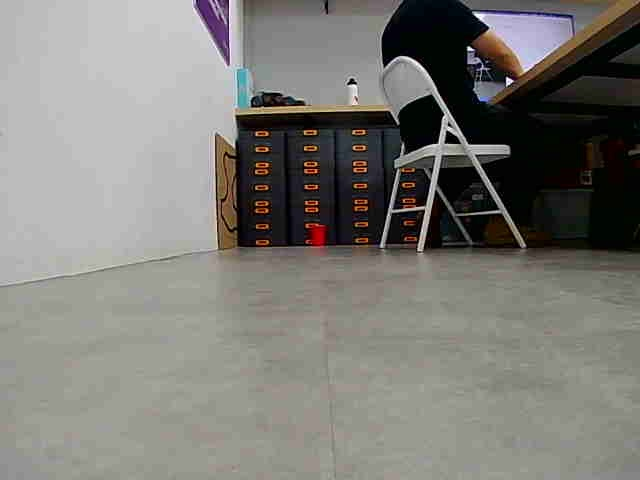

In [33]:
import numpy as np
import cv2
from IPython.display import clear_output,display, Image

got.open_camera()
print("The camera is on.")

for i in range(100):
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue

    picture_1D  = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

In [ ]:
import time

got.open_camera()
print("The camera is on.")

start_time = time.time()
while time.time() - start_time<5:
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue

    picture_1D  = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

2. UGOT camera video with bounding box

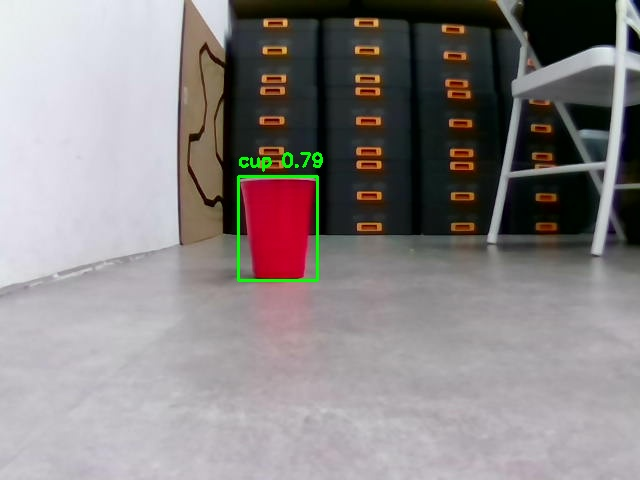

In [14]:
import time 

got.open_camera()
print("The camera is on.")

start_time = time.time()
while time.time() - start_time<5:
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    frame = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)
    
    # YOLO block
    results = model(frame,verbose = False)
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        conf = float(box.conf[0])
        name = model.names[class_id]
        x1,y1,x2,y2 = map(int,box.xyxy[0])
        cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

2. object recognition

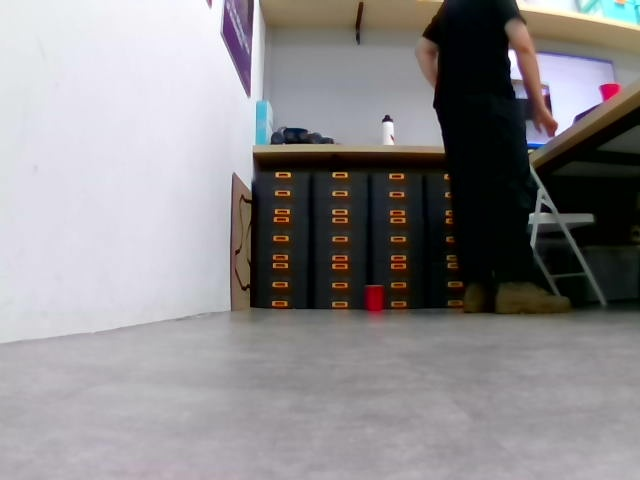

In [26]:
import time 

got.open_camera()
print("The camera is on.")

start_time = time.time()
while time.time() - start_time<10:
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    frame = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)
    
    # YOLO block
    results = model(frame,verbose = False)
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        conf = float(box.conf[0])
        name = model.names[class_id]
        if name =="cup":
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cx = (x1+x2)//2
            cy = (y1+y2)//2
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
            cv2.circle(frame,(cx,cy),3,(0,255,0),2)
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

## Session 6

1. vehicle rotate and object recognition

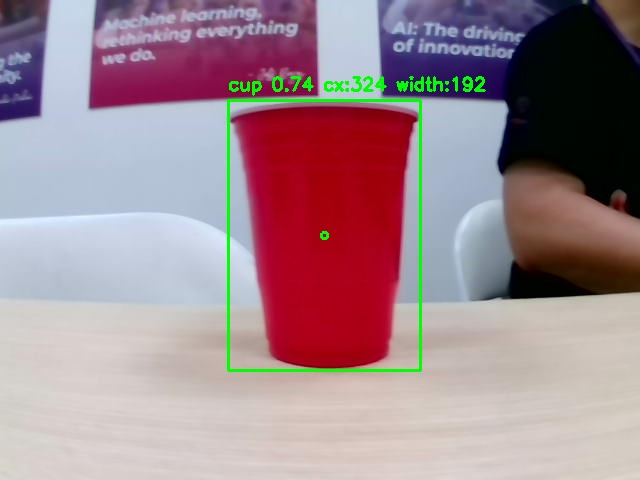

In [21]:
import time 

got.open_camera()
print("The camera is on.")

start_time = time.time()
while True:
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    frame = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)
    
    # YOLO block
    results = model(frame,verbose = False)
    cx = None #flag
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        conf = float(box.conf[0])
        name = model.names[class_id]
        if name =="cup":
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cup_width = x2-x1
            cx = (x1+x2)//2
            cy = (y1+y2)//2
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(frame,f"{name} {conf:.2f} cx:{cx} width:{cup_width}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
            cv2.circle(frame,(cx,cy),3,(0,255,0),2)
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)
    
    # object recognized and centralized
    if cx and cx > 320:
        got.mecanum_stop()
        break
    
    got.mecanum_move_xyz(0,0,20)

2. flag

In [22]:
names = ["John","Colley","Ryan","Jack"]
target = "Jack"

for name in names:
    if name==target:
        print(f"I have found {target}")
    else:
        print(f"{target} is not found.")

Jack is not found.
Jack is not found.
Jack is not found.
I have found Jack


In [23]:
# boolean flag
names = ["John","Colley","Ryan","Jack"]
target = "Jack"

found = False
for name in names:
    if name==target:
        found = True
        break
    
if found:
    print(f"I have found {target}")
else:
    print(f"{target} is not found.")

I have found Jack


3. vehicle approach, object recognition and stop

In [34]:
import time 

got.open_camera()
print("The camera is on.")

start_time = time.time()
while True:
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    frame = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)
    
    # YOLO block
    results = model(frame,verbose = False)
    cx = None #flag
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        conf = float(box.conf[0])
        name = model.names[class_id]
        if name =="cup":
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cup_width = x2-x1
            cx = (x1+x2)//2
            cy = (y1+y2)//2
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(frame,f"{name} {conf:.2f} cx:{cx} width:{cup_width}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
            cv2.circle(frame,(cx,cy),3,(0,255,0),2)
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)
    
    # object recognized and centralized
    if cx and cup_width > 100:
        got.mecanum_stop()
        break
    
    got.mecanum_move_xyz(0,15,0)

KeyboardInterrupt: 